# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Viditp25/flyrank-intern-/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

Dataset rows: 30,000
Dataset columns: 44

Available columns:
['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'content_age_days', 'age_tier', 'age_tier_order', 'days_since_last_update', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'impression_tier', 'position_tier', 'trend_direction', 'trend_pct']

Numeric field summary:


,count,mean,std,min,10%,25%,50%,75%,90%,max
trend_pct,26612.0,-4.785969,473.861780,-100.0,-85.39,-62.6,-33.50,0.00,50.00,44900.0
days_since_last_update,30000.0,46.098300,42.078709,1.0,13.00,20.0,20.00,104.00,104.00,373.0
impressions_90d,30000.0,5200.366300,16838.019547,1.0,5.00,81.0,731.00,3615.25,12136.40,517715.0
sessions_90d,30000.0,37.066633,107.069131,1.0,1.00,2.0,7.00,27.00,88.00,4345.0
word_count,22301.0,3107.760325,1452.382598,8.0,1382.00,2413.0,2877.00,3666.00,5327.00,9546.0
avg_position,30000.0,16.342380,15.216790,0.0,3.70,6.2,10.80,22.30,36.80,245.0
ctr,30000.0,0.510733,3.279162,0.0,0.00,0.0,0.07,0.29,0.65,100.0
engagement_rate,30000.0,2.534520,8.310096,0.0,0.00,0.0,0.00,1.35,6.94,100.0



Missing values in selected fields:


,missing_count
trend_pct,3388
days_since_last_update,0
impressions_90d,0
sessions_90d,0
word_count,7699
avg_position,0
ctr,0
engagement_rate,0


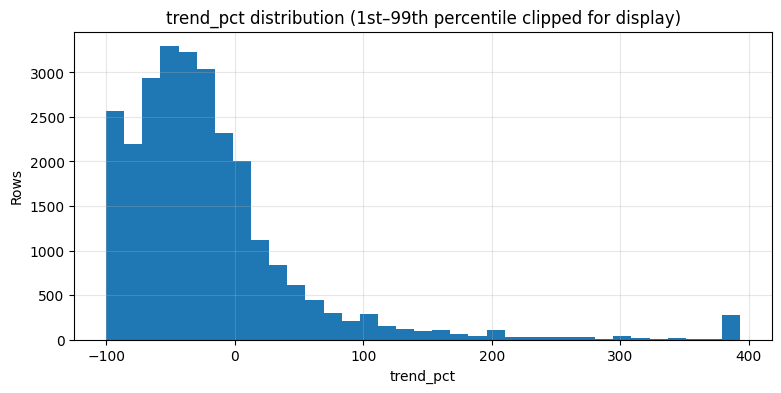

trend_pct 1st percentile: -100.00
trend_pct 99th percentile: 393.25
Actual maximum trend_pct: 44900.00


In [1]:
# Section 1: Load the anonymized dataset and inspect distributions

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATHS = [
    Path("data/raw/content_refresh_anonymized.csv"),
    Path("../data/raw/content_refresh_anonymized.csv"),
    Path("/content/flyrank-intern-/data/raw/content_refresh_anonymized.csv"),
]

data_path = next((p for p in DATA_PATHS if p.exists()), None)

if data_path is not None:
    df = pd.read_csv(data_path)
else:
    # Public anonymized dataset from the project repository
    data_url = (
        "https://raw.githubusercontent.com/Viditp25/"
        "flyrank-intern-/main/data/raw/content_refresh_anonymized.csv"
    )
    df = pd.read_csv(data_url)

print(f"Dataset rows: {len(df):,}")
print(f"Dataset columns: {len(df.columns)}")
print("\nAvailable columns:")
print(df.columns.tolist())

# Inspect important numeric fields that actually exist
numeric_candidates = [
    "trend_pct",
    "days_since_last_update",
    "impressions_90d",
    "sessions_90d",
    "word_count",
    "avg_position",
    "ctr",
    "engagement_rate",
]

numeric_cols = [c for c in numeric_candidates if c in df.columns]

print("\nNumeric field summary:")
display(df[numeric_cols].describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]).T)

print("\nMissing values in selected fields:")
display(df[numeric_cols].isna().sum().to_frame("missing_count"))

# Plot trend_pct separately because it can have a heavy tail
if "trend_pct" in df.columns:
    trend = pd.to_numeric(df["trend_pct"], errors="coerce").dropna()

    if len(trend):
        lower, upper = trend.quantile([0.01, 0.99])
        plt.figure(figsize=(9, 4))
        plt.hist(trend.clip(lower=lower, upper=upper), bins=35)
        plt.title("trend_pct distribution (1st–99th percentile clipped for display)")
        plt.xlabel("trend_pct")
        plt.ylabel("Rows")
        plt.grid(True, alpha=0.3)
        plt.show()

        print(f"trend_pct 1st percentile: {lower:.2f}")
        print(f"trend_pct 99th percentile: {upper:.2f}")
        print(f"Actual maximum trend_pct: {trend.max():.2f}")

## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

In [2]:
# Section 2: Descriptive signal tests against observed trend_direction

import pandas as pd
import numpy as np

if "trend_direction" not in df.columns:
    raise ValueError(
        "The dataset does not contain trend_direction. "
        "Check that the correct anonymized CSV was loaded."
    )

audit_df = df.copy()
audit_df["trend_direction"] = (
    audit_df["trend_direction"].astype("string").str.lower().str.strip()
)

valid_labels = {"down", "stable", "up"}
audit_df = audit_df[audit_df["trend_direction"].isin(valid_labels)].copy()
audit_df["is_observed_down"] = (
    audit_df["trend_direction"].eq("down").astype(int)
)

print(f"Rows with recognized trend labels: {len(audit_df):,}")
print("\nObserved trend distribution:")
display(
    audit_df["trend_direction"]
    .value_counts(dropna=False)
    .rename_axis("trend_direction")
    .to_frame("row_count")
)

def compare_signal(df_in, column, bins=4):
    """Compare an available signal across observed trend labels."""
    if column not in df_in.columns:
        print(f"\n{column}: unavailable (column not found)")
        return

    temp = df_in[[column, "trend_direction", "is_observed_down"]].copy()
    temp[column] = pd.to_numeric(temp[column], errors="coerce")
    temp = temp.dropna(subset=[column])

    if temp[column].nunique() < 2:
        print(f"\n{column}: unavailable (fewer than two distinct values)")
        return

    try:
        temp["signal_group"] = pd.qcut(
            temp[column],
            q=bins,
            duplicates="drop"
        )
    except ValueError:
        print(f"\n{column}: could not create useful quantile groups")
        return

    summary = (
        temp.groupby("signal_group", observed=False)
        .agg(
            n=("is_observed_down", "size"),
            observed_down_rate=("is_observed_down", "mean"),
            median_signal=(column, "median"),
        )
        .reset_index()
    )

    summary["observed_down_rate_pct"] = (
        summary["observed_down_rate"] * 100
    ).round(2)

    print(f"\nSignal test: {column}")
    display(summary)

    if len(summary) >= 2:
        low_rate = summary.iloc[0]["observed_down_rate"]
        high_rate = summary.iloc[-1]["observed_down_rate"]

        print(
            f"Observed-down rate in lowest group: {low_rate:.3f}; "
            f"highest group: {high_rate:.3f}"
        )
        print(
            "Interpretation: descriptive association only; "
            "this does not establish causation or future refresh impact."
        )

# Test 1: freshness / update age
compare_signal(audit_df, "days_since_last_update")

# Test 2: prior visibility / impressions
compare_signal(audit_df, "impressions_90d")

# Test 3: content depth
compare_signal(audit_df, "word_count")

Rows with recognized trend labels: 26,612

Observed trend distribution:


,row_count
trend_direction,
down,16262
stable,5962
up,4388



Signal test: days_since_last_update


,signal_group,n,observed_down_rate,median_signal,observed_down_rate_pct
0,"(0.999, 20.0]",12992,0.658097,20.0,65.81
1,"(20.0, 22.0]",3493,0.401374,22.0,40.14
2,"(22.0, 104.0]",9878,0.621178,104.0,62.12
3,"(104.0, 373.0]",249,0.698795,183.0,69.88


Observed-down rate in lowest group: 0.658; highest group: 0.699
Interpretation: descriptive association only; this does not establish causation or future refresh impact.

Signal test: impressions_90d


,signal_group,n,observed_down_rate,median_signal,observed_down_rate_pct
0,"(0.999, 196.0]",6656,0.639724,47.0,63.97
1,"(196.0, 1029.0]",6652,0.608689,498.0,60.87
2,"(1029.0, 4406.0]",6652,0.640108,2086.0,64.01
3,"(4406.0, 517715.0]",6652,0.555773,10886.0,55.58


Observed-down rate in lowest group: 0.640; highest group: 0.556
Interpretation: descriptive association only; this does not establish causation or future refresh impact.

Signal test: word_count


,signal_group,n,observed_down_rate,median_signal,observed_down_rate_pct
0,"(423.999, 2523.0]",4798,0.680700,1549.5,68.07
1,"(2523.0, 2900.0]",4792,0.627504,2724.0,62.75
2,"(2900.0, 3688.0]",4793,0.652618,3140.0,65.26
3,"(3688.0, 9546.0]",4784,0.685201,5152.5,68.52


Observed-down rate in lowest group: 0.681; highest group: 0.685
Interpretation: descriptive association only; this does not establish causation or future refresh impact.


## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

In [3]:
# Section 3: Test a staleness-related baseline rule
# against the observed trend label.
#
# Rule under review:
# days_since_last_update >= 180 AND impressions_90d >= 500
#
# This flag is calculated from the documented rule below.
# It is not claimed to be a stored production flag.

required_columns = [
    "days_since_last_update",
    "impressions_90d",
    "trend_direction",
]

missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError(f"Required columns missing: {missing}")

flag_df = df[required_columns].copy()

for col in ["days_since_last_update", "impressions_90d"]:
    flag_df[col] = pd.to_numeric(flag_df[col], errors="coerce")

flag_df["trend_direction"] = (
    flag_df["trend_direction"].astype("string").str.lower().str.strip()
)

flag_df = flag_df[
    flag_df["trend_direction"].isin(["down", "stable", "up"])
].copy()

flag_df["is_observed_down"] = (
    flag_df["trend_direction"].eq("down").astype(int)
)

flag_df["stale_visible_page"] = (
    flag_df["days_since_last_update"].ge(180)
    & flag_df["impressions_90d"].ge(500)
)

flag_df["staleness_flag_group"] = np.where(
    flag_df["stale_visible_page"],
    "Rule matched",
    "Rule not matched"
)

flag_summary = (
    flag_df.groupby("staleness_flag_group")
    .agg(
        rows=("is_observed_down", "size"),
        observed_down_count=("is_observed_down", "sum"),
        observed_down_rate=("is_observed_down", "mean"),
        median_days_since_update=("days_since_last_update", "median"),
        median_impressions_90d=("impressions_90d", "median"),
    )
    .reset_index()
)

flag_summary["observed_down_rate_pct"] = (
    flag_summary["observed_down_rate"] * 100
).round(2)

print("Staleness rule:")
print("days_since_last_update >= 180 AND impressions_90d >= 500")
display(flag_summary)

print(
    "\nInterpretation: this compares the rule-matched group with the "
    "remaining group using an observed trend label. It does not establish "
    "that the rule predicts future decline or that refreshing pages "
    "will improve performance."
)

print(
    "\nNo stored priority score or reason-code field is assumed here. "
    "This test evaluates the documented staleness rule only."
)

Staleness rule:
days_since_last_update >= 180 AND impressions_90d >= 500


,staleness_flag_group,rows,observed_down_count,observed_down_rate,median_days_since_update,median_impressions_90d,observed_down_rate_pct
0,Rule matched,17,16,0.941176,194.0,4429.0,94.12
1,Rule not matched,26595,16246,0.610867,22.0,1028.0,61.09



Interpretation: this compares the rule-matched group with the remaining group using an observed trend label. It does not establish that the rule predicts future decline or that refreshing pages will improve performance.

No stored priority score or reason-code field is assumed here. This test evaluates the documented staleness rule only.


## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

In [4]:
# Section 4: Practical takeaway based on the analyses above

print("Practical takeaway")
print("-------------------")
print(
    "The observed dataset can help prioritize pages for human review "
    "using signals such as update age, prior impressions, and content depth."
)
print(
    "The signal comparisons and staleness-rule analysis are descriptive "
    "associations, not evidence of causation or future performance."
)
print(
    "Before operational use, verify that features are available at the "
    "decision time, investigate missing values and extreme observations, "
    "and validate the rule on a separate time period or client group."
)

Practical takeaway
-------------------
The observed dataset can help prioritize pages for human review using signals such as update age, prior impressions, and content depth.
The signal comparisons and staleness-rule analysis are descriptive associations, not evidence of causation or future performance.
Before operational use, verify that features are available at the decision time, investigate missing values and extreme observations, and validate the rule on a separate time period or client group.


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.